# 02 · Evaluación del juez (Wasserstein) y demo del selector de estrategia

1. Carga el modelo base 4-bit + adaptador LoRA (el mismo modelo sirve como *base* con `disable_adapter()` y como *fine-tuned*).
2. **Evaluación**: distribución de scores del juez vs. humanos en el test (262), con Wasserstein Distance (Tabla 2 del paper, pero sobre el test original y no sobre los 1.180 escenarios nuevos, que no están publicados).
3. **Demo**: genera un grupo de 5, calcula las 6 estrategias, el juez puntúa cada candidata 5 veces y se recomienda el 4.º ítem de la ganadora (sección 3.2.1).

Sube a `PROJECT_DIR`: `config_gen.py`, `strats.py`, `test_v5_2.jsonl`.

In [1]:
!pip install -q -U transformers peft datasets bitsandbytes accelerate scipy pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ------------------------- CONFIGURACION -------------------------
PROJECT_DIR = '/content/drive/MyDrive/seminario_recsys'
MODEL = 'olmo'                                       # 'olmo' o 'llama'
ADAPTER_DIR = f'/content/drive/MyDrive/judgmental_{MODEL}'   # smoke: agrega '_smoke'. Si el entrenamiento se corto: usa el mejor checkpoint, p.ej. .../judgmental_olmo/checkpoint-2000
N_EVAL = 262          # cuantos ejemplos del test evaluar (baja a ~60 para probar rapido)
TEMPERATURE = 0.7     # el paper no especifica los parametros de muestreo del juez
# -----------------------------------------------------------------
BASES = {'llama': 'meta-llama/Meta-Llama-3.1-8B-Instruct',
         'olmo': 'allenai/Olmo-3-7B-Instruct-SFT'}

import sys, os
sys.path.insert(0, PROJECT_DIR)

# Verifica que esten los archivos necesarios antes de seguir
_need = ['config_gen.py', 'strats.py', 'test_v5_2.jsonl']
_missing = [f for f in _need if not os.path.exists(os.path.join(PROJECT_DIR, f))]
for f in _need:
    print(('OK      ' if f not in _missing else 'FALTA   ') + os.path.join(PROJECT_DIR, f))
if _missing:
    raise FileNotFoundError(f'Sube {_missing} a {PROJECT_DIR} (o corrige PROJECT_DIR) y vuelve a ejecutar esta celda.')
if not os.path.isdir(ADAPTER_DIR):
    print('AVISO: no existe ADAPTER_DIR =', ADAPTER_DIR, '-> corrigelo antes de cargar el modelo')
try:
    from google.colab import userdata
    from huggingface_hub import login
    login(token=userdata.get('HF_TOKEN'))
except Exception as e:
    print('Sin HF_TOKEN:', e)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      /content/drive/MyDrive/seminario_recsys/config_gen.py
OK      /content/drive/MyDrive/seminario_recsys/strats.py
OK      /content/drive/MyDrive/seminario_recsys/test_v5_2.jsonl
Sin HF_TOKEN: Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.


In [11]:
# ---------- Utilidades (sin GPU): parseo, WD, prompt, estrategias, selector ----------
import re, json, random
import numpy as np
import pandas as pd
from config_gen import (generate_uniform_conf, generate_divergent_conf,
                        generate_minorty_conf, generate_coalitional_conf)
from strats import ADD, APP, LMS, MPL, MAJ, FAI

DIMS = ['Fairness', 'Consensus', 'Satisfaction']
LIKERT = list(range(-3, 4))

def parse_scores(text):
    # Lee 'Fairness: -3' etc. despues del ultimo 'Scores'. None si falta alguna dimension.
    tail = text.split('Scores')[-1]
    out = {}
    for d in DIMS:
        m = re.findall(rf'{d}[\s*]*:[\s*]*(-?\d)', tail)
        if m and -3 <= int(m[-1]) <= 3:
            out[d] = int(m[-1])
    return out if len(out) == 3 else None

def wasserstein_likert(a, b):
    # WD entre dos muestras ordinales en -3..3: suma_k |F(k) - G(k)| (CDFs)
    fa = np.cumsum([np.mean(np.array(a) == k) for k in LIKERT])
    fb = np.cumsum([np.mean(np.array(b) == k) for k in LIKERT])
    return float(np.abs(fa - fb).sum())

_test = [json.loads(l) for l in open(f'{PROJECT_DIR}/test_v5_2.jsonl', encoding='utf8')]
SYSTEM_PROMPT = _test[0]['messages'][0]['content']   # el mismo que se uso en el fine-tuning

_USER_EX = _test[0]['messages'][1]['content']   # plantilla exacta usada en el entrenamiento

def build_messages(table, visited, rec):
    u = re.sub(r'### BEGIN TABLE ###\n.*?\n### END TABLE ###',
               lambda m: '### BEGIN TABLE ###\n' + str(table) + '\n### END TABLE ###', _USER_EX, flags=re.S)
    u = re.sub(r'(last 3 restaurants visited are: ).*?(\*\*\.)',
               lambda m: m.group(1) + ', '.join(visited) + m.group(2), u)
    u = re.sub(r'\*\*rest_\d+\*\*( has been recommended)',
               lambda m: '**' + rec + '**' + m.group(1), u)
    return [{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': u}]

CONFIGS = {
    'uniform': generate_uniform_conf, 'divergent': generate_divergent_conf,
    'minority': generate_minorty_conf, 'coalitional': generate_coalitional_conf,
}

def make_group(config, seed=None):
    if seed is not None:
        random.seed(seed)
    matrix = CONFIGS[config](n=5, m=10, r=5)
    return {r: [m[r] for m in matrix] for r in matrix[0].keys()}   # restaurante -> 5 ratings

NAMES = ['Alex', 'Bob', 'Carl', 'David', 'Elle']

def run_strategy(name, table):
    df = pd.DataFrame([{'item': i, 'rating': r} for i, rs in table.items() for r in rs])
    if name == 'ADD': return ADD(df)
    if name == 'APP': return APP(df, threshold=3)     # ojo: el default de strats.py (6) no sirve con escala 1-5
    if name == 'LMS': return LMS(df)
    if name == 'MPL': return MPL(df)
    if name == 'MAJ': return MAJ(table)
    if name == 'FAI': return FAI({**table, 'names': NAMES})
    raise ValueError(name)

STRATEGIES = ['ADD', 'APP', 'LMS', 'MPL', 'MAJ', 'FAI']

def select_strategy(table, judge_fn, n_assess=5, metric='mean', verbose=True):
    # judge_fn(list_de_mensajes) -> list de dict {'Fairness','Consensus','Satisfaction'} (None si fallo el parseo)
    rows = []
    for s in STRATEGIES:
        order = run_strategy(s, table)
        if len(order) < 4:          # p.ej. APP con pocos items sobre el umbral
            rows.append(dict(strategy=s, rec=None, order=order)); continue
        visited, rec = order[:3], order[3]
        res = [r for r in judge_fn([build_messages(table, visited, rec)] * n_assess) if r]
        row = dict(strategy=s, rec=rec, visited=visited, n_ok=len(res), order=order)
        for d in DIMS:
            row[d] = float(np.mean([r[d] for r in res])) if res else np.nan
        row['mean'] = float(np.nanmean([row[d] for d in DIMS])) if res else np.nan
        rows.append(row)
    df = pd.DataFrame(rows)
    ok = df.dropna(subset=['rec', metric])
    best = ok.sort_values(metric, ascending=False).iloc[0]
    if verbose:
        print(df[['strategy', 'rec', 'Fairness', 'Consensus', 'Satisfaction', 'mean']].round(2).to_string(index=False))
        print(f"\nEstrategia elegida: {best['strategy']}  ->  recomendar {best['rec']}")
    return best, df

In [12]:
# ---------- Carga del modelo (4-bit NF4) + adaptador LoRA ----------
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import PeftModel

name = BASES[MODEL]
tok = AutoTokenizer.from_pretrained(name, padding_side='left')
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
base = AutoModelForCausalLM.from_pretrained(
    name, device_map='auto', dtype=dtype,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                           bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=dtype))
model = PeftModel.from_pretrained(base, ADAPTER_DIR).eval()
print('Modelo + adaptador cargados')

Loading weights:   0%|          | 0/355 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Modelo + adaptador cargados


In [13]:
from contextlib import nullcontext

@torch.no_grad()
def generate_texts(msgs_list, use_adapter=True, batch_size=16, max_new_tokens=700):
    outs = []
    for i in range(0, len(msgs_list), batch_size):
        prompts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                   for m in msgs_list[i:i + batch_size]]
        enc = tok(prompts, return_tensors='pt', padding=True, add_special_tokens=False).to(model.device)
        ctx = nullcontext() if use_adapter else model.disable_adapter()
        with ctx:
            g = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True,
                               temperature=TEMPERATURE, top_p=0.95, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(g[:, enc['input_ids'].shape[1]:], skip_special_tokens=True)
    return outs

def judge_finetuned(msgs_list):
    return [parse_scores(t) for t in generate_texts(msgs_list, use_adapter=True)]

# prueba rapida
t = generate_texts([_test[0]['messages'][:2]])[0]
print(t); print(parse_scores(t))

Fairness reasoning: Score -3 The suggestion of rest_4 feels blatantly unfair because member 2 and member 3 each rated it only 1 star, meaning the group is being pushed toward a place that they absolutely dislike. It ignores their strong negative feelings, which makes the decision appear biased toward the higher‑rated members. A fairer choice would avoid restaurants that any member rates so poorly.

Consensus reasoning: Score -3 There is virtually no consensus for rest_4; the ratings are split 5, 1, 1, 4, 3, showing a huge gap between the most and least enthusiastic members. Such a polarized spread indicates the group cannot agree on this option. Consensus would improve if the chosen restaurant had a tighter rating range, say all members giving at least 3 stars.

Satisfaction reasoning: Score -3 Overall satisfaction is likely to be very low because two people gave the restaurant the lowest possible rating, dragging down the group’s enjoyment despite a couple of higher scores. The strong

## A. Evaluación: juez vs. humanos (Wasserstein)
Compara, sobre los mismos escenarios del test, los scores humanos con los del modelo base (adaptador desactivado) y el fine-tuned. Menor WD = mejor.

In [14]:
import random as _r
_r.seed(0); torch.manual_seed(0)
sample = _r.sample(_test, min(N_EVAL, len(_test)))
msgs = [ex['messages'][:2] for ex in sample]
human = [parse_scores(ex['messages'][2]['content']) for ex in sample]
assert all(human), 'no se pudo parsear algun score humano'

res = {}
for label, use in [('base', False), ('fine-tuned', True)]:
    texts = generate_texts(msgs, use_adapter=use)
    parsed = [parse_scores(t) for t in texts]
    print(f'{label}: {sum(p is None for p in parsed)} salidas sin parsear de {len(parsed)}')
    res[label] = parsed

rows = []
for d in DIMS:
    h = [x[d] for x in human]
    row = {'dim': d, 'humanos mean': np.mean(h), 'humanos std': np.std(h)}
    for label, parsed in res.items():
        v = [p[d] for p in parsed if p]
        row[f'WD {label}'] = wasserstein_likert(v, h)
        row[f'mean {label}'] = np.mean(v); row[f'std {label}'] = np.std(v)
    rows.append(row)
pd.DataFrame(rows).round(2)

base: 34 salidas sin parsear de 262
fine-tuned: 1 salidas sin parsear de 262


,dim,humanos mean,humanos std,WD base,mean base,std base,WD fine-tuned,mean fine-tuned,std fine-tuned
0,Fairness,0.48,1.72,0.25,0.45,1.65,0.30,0.29,2.03
1,Consensus,0.57,1.65,0.55,0.11,1.55,0.34,0.37,1.94
2,Satisfaction,0.42,1.55,0.26,0.22,1.47,0.47,0.53,1.98


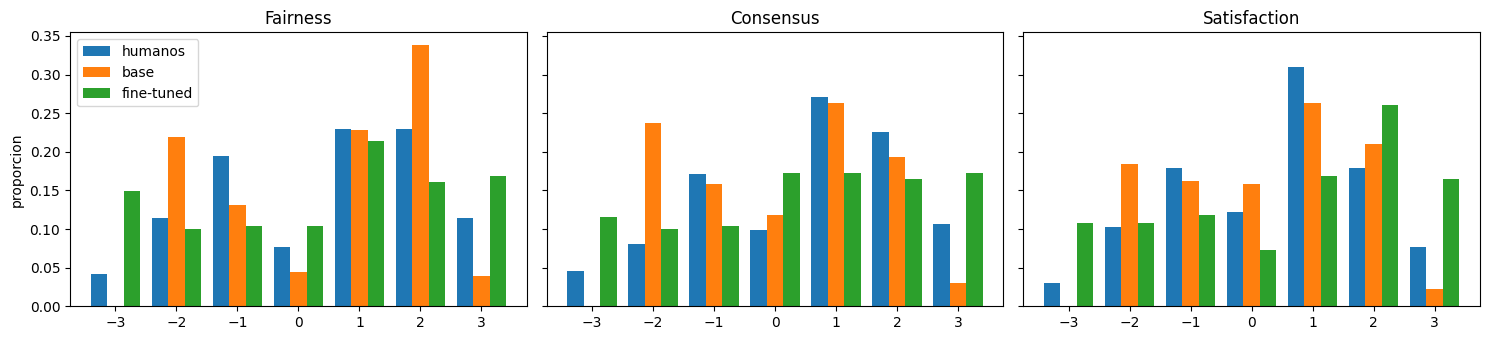

In [15]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, d in zip(axs, DIMS):
    series = {'humanos': [x[d] for x in human]}
    series.update({k: [p[d] for p in v if p] for k, v in res.items()})
    w = 0.27
    for j, (k, v) in enumerate(series.items()):
        ax.bar(np.array(LIKERT) + (j - 1) * w, [np.mean(np.array(v) == k_) for k_ in LIKERT], w, label=k)
    ax.set_title(d); ax.set_xticks(LIKERT)
axs[0].legend(); axs[0].set_ylabel('proporcion'); plt.tight_layout(); plt.show()

## B. Demo: el juez elige la estrategia de agregación
Pipeline de la sección 3.2.1: 6 estrategias → 5 assessments cada una (30 inferencias) → promedio → ranking → se recomienda el **4.º ítem** de la estrategia ganadora.
Cambia `CONFIG` (`uniform`, `divergent`, `minority`, `coalitional`) y `SEED`.

In [16]:
CONFIG, SEED = 'coalitional', 7
table = make_group(CONFIG, seed=SEED)
print(pd.DataFrame(table, index=NAMES).T.to_string())     # filas = restaurantes, columnas = miembros
import time; t0 = time.time()
best, detail = select_strategy(table, judge_finetuned, n_assess=5, metric='mean')
print(f'\nTiempo: {time.time() - t0:.0f} s para 30 inferencias')

         Alex  Bob  Carl  David  Elle
rest_1      1    4     3      1     2
rest_2      2    4     5      4     5
rest_3      1    1     2      3     3
rest_4      5    4     1      1     1
rest_5      2    3     5      5     3
rest_6      3    5     2      2     1
rest_7      4    5     1      1     3
rest_8      2    3     2      5     5
rest_9      5    5     3      2     3
rest_10     1    1     1      3     2
strategy    rec  Fairness  Consensus  Satisfaction  mean
     ADD rest_8       2.4        2.4           2.4  2.40
     APP rest_7      -0.8       -0.6          -0.8 -0.73
     LMS rest_9      -0.2       -0.2           0.2 -0.07
     MPL rest_7      -0.6       -0.8          -0.8 -0.73
     MAJ rest_8       1.4        1.6           1.8  1.60
     FAI rest_5       1.2        1.8           1.6  1.53

Estrategia elegida: ADD  ->  recomendar rest_8

Tiempo: 358 s para 30 inferencias


In [19]:
# Para comparar: que recomendaria cada estrategia por si sola
detail[['strategy', 'rec', 'visited', 'Fairness', 'Consensus', 'Satisfaction', 'mean']].round(2)

,strategy,rec,visited,Fairness,Consensus,Satisfaction,mean
0,ADD,rest_8,"[rest_2, rest_5, rest_9]",2.4,2.4,2.4,2.40
1,APP,rest_7,"[rest_2, rest_4, rest_5]",-0.8,-0.6,-0.8,-0.73
2,LMS,rest_9,"[rest_5, rest_2, rest_8]",-0.2,-0.2,0.2,-0.07
3,MPL,rest_7,"[rest_4, rest_2, rest_8]",-0.6,-0.8,-0.8,-0.73
4,MAJ,rest_8,"[rest_2, rest_5, rest_9]",1.4,1.6,1.8,1.60
5,FAI,rest_5,"[rest_4, rest_6, rest_2]",1.2,1.8,1.6,1.53
